# Safe@Sea Wave and Icing Data Loader (year 2026)

This notebook follows the Safe@Sea workflow pattern from the DESP template and loads daily Safe@Sea forecast files for **January-October 2026** from the public object store.

It loads two variables by default:
- `swh` (significant wave height, m)
- `icing` (vessel icingm, mm/h)
- `ice` (sea ice fraction, 0-1)

Each daily run contains a 2-day forecast, so times overlap between files; this notebook merges and de-duplicates by timestamp.

In [1]:
import datetime as dt
import os

import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.path import Path
import numpy as np
import pandas as pd
import xarray as xr
import zarr

from metocean_stats import TimeSeries, Variable

In [2]:
BASE_URL = "https://safeatsea.s3.gra.io.cloud.ovh.net"
VARIABLES = ["swh", "icing","ice"]

MONTH_START = dt.date(2026, 1, 1)
MONTH_END = dt.date(2026, 3, 31)
INIT_DATES = pd.date_range(MONTH_START, MONTH_END, freq="D")

print(f"Zarr version: {zarr.__version__}")
print(f"Forecast initialization dates: {len(INIT_DATES)} ({INIT_DATES[0].date()} to {INIT_DATES[-1].date()})")

Zarr version: 3.2.1
Forecast initialization dates: 90 (2026-01-01 to 2026-03-31)


In [3]:
def safeatsea_filename(var: str, init_date: dt.date) -> str:
    end_date = init_date + dt.timedelta(days=2)
    return f"{var}_{init_date:%Y%m%d}T0000Z_{end_date:%Y%m%d}T0000Z_SafeAtSea.zarr"


def open_safeatsea_zarr(url: str) -> xr.Dataset:
    zarr_major = int(zarr.__version__.split(".")[0])
    if zarr_major >= 3:
        return xr.open_zarr(url, consolidated=True, zarr_format=2)
    return xr.open_zarr(url)

In [4]:
monthly_data = {var: [] for var in VARIABLES}
missing_files = {
    var: [] for var in VARIABLES}

for ts in INIT_DATES:
    init_date = ts.date()
    daily_datasets = []

    for var in VARIABLES:
        fname = safeatsea_filename(var, init_date)
        url = os.path.join(BASE_URL, fname)

        try:
            ds = open_safeatsea_zarr(url)[[var]]
            ds = ds.assign_coords(init_time=np.datetime64(init_date))
            daily_datasets.append(ds)
        except Exception as exc:
            missing_files[var].append({
                "init_date": str(init_date),
                "url": url,
                "error": str(exc)[:200],
            })

    if not daily_datasets:
        continue

    merged = xr.merge(daily_datasets, compat="override")
    merged = merged.sortby("time")
    merged = merged.sel(time=~merged.indexes["time"].duplicated())

    for var in VARIABLES:
        if var in merged:
            monthly_data[var].append(merged[[var]])

for var in VARIABLES:
    if monthly_data[var]:
        monthly_data[var] = xr.concat(monthly_data[var], dim="time").sortby("time")
        monthly_data[var] = monthly_data[var].sel(time=~monthly_data[var].indexes["time"].duplicated())

print("Load complete.")

/tmp/nummelin/3152888/ipykernel_1181446/1311147884.py:15: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds = ds.assign_coords(init_time=np.datetime64(init_date))
/tmp/nummelin/3152888/ipykernel_1181446/1311147884.py:15: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor;

Load complete.


In [14]:
for var in VARIABLES:
    print(f"\nVariable: {var}")
    print(f"  Missing files: {len(missing_files.get(var, []))}")

    if var in monthly_data and monthly_data[var]:
        ds = monthly_data[var]
        t0 = pd.to_datetime(ds.time.min().values)
        t1 = pd.to_datetime(ds.time.max().values)
        print(f"  Time coverage: {t0} to {t1}")
        print(f"  Number of timesteps: {ds.sizes.get('time', 0)}")
        print(ds)
    else:
        print("  No dataset was loaded for this variable.")


Variable: swh
  Missing files: 48
  Time coverage: 2026-01-05 00:00:00 to 2026-04-02 00:00:00
  Number of timesteps: 1083
<xarray.Dataset> Size: 10GB
Dimensions:    (time: 1083, latitude: 1402, longitude: 823)
Coordinates:
  * time       (time) datetime64[ns] 9kB 2026-01-05 ... 2026-04-02
  * longitude  (longitude) float32 3kB 5.651 5.684 5.717 ... 32.98 33.02 33.05
  * latitude   (latitude) float32 6kB 68.0 68.01 68.02 ... 80.53 80.54 80.55
    init_time  (time) datetime64[ns] 9kB 2026-01-05 2026-01-05 ... 2026-03-31
Data variables:
    swh        (time, latitude, longitude) float64 10GB dask.array<chunksize=(7, 351, 206), meta=np.ndarray>
Attributes: (12/17)
    WAVEWATCH_III_version_number:  7.14
    WAVEWATCH_III_switches:        NOGRB SHRD PR3 UQ FLX0 LN1 ST4 STAB0 NL1 B...
    product_name:                  WaveExtremes DT 1km operational wave model...
    area:                          1km operational domain covering: Barents Sea
    latitude_resolution:           0.
    longit

## Visualize the data on a map

Let's just plot a map to see what we are dealing with.

In [5]:
# Select the final day of March 2026 and use the last forecast step on that date - load the data
march_day = "2026-03-31"
barents_swh = monthly_data["swh"].sel(
    time=slice(f"{march_day} 00:00:00", f"{march_day} 23:59:59"),
    latitude=slice(68.0, 80.7),
    longitude=slice(5.0, 33.0),
).isel(time=-1).load()
barents_ice = monthly_data["ice"].sel(
    time=slice(f"{march_day} 00:00:00", f"{march_day} 23:59:59"),
    latitude=slice(68.0, 80.7),
    longitude=slice(5.0, 33.0),
).isel(time=-1).load()

swh_field = barents_swh["swh"].where(np.isfinite(barents_swh["swh"]))
ice_field = barents_ice["ice"].where(barents_ice["ice"] >= 0.15)

lon_2d, lat_2d = np.meshgrid(barents_swh["longitude"].values, barents_swh["latitude"].values)

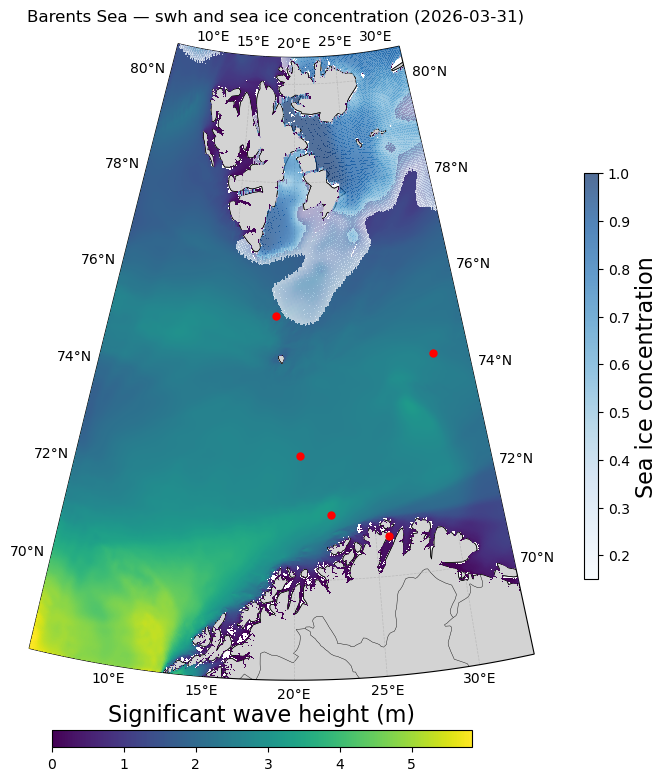

In [6]:
# THEN TO THE ACTUAL PLOTTING
POINTS_LAT = [75.3,74.33,70.806,71.3,72.5]
POINTS_LON = [18.6,30.4,25.818,22.3,20.4]
#
fig, ax = plt.subplots(
    1, 1,
    figsize=(7, 7),
    subplot_kw={"projection": ccrs.NearsidePerspective(central_longitude=20.0, central_latitude=72.0, satellite_height=2.5e7)},
    constrained_layout=True,
)

ax.set_extent([5.0, 33.0, 68.0, 80.7], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray", edgecolor="black", linewidth=0.4, zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.5, zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.3, zorder=2)
ax.gridlines(draw_labels=True, linestyle="--", linewidth=0.5, alpha=0.7)

lon_bounds = np.array([barents_swh["longitude"].values[0], barents_swh["longitude"].values[-1]])
lat_bounds = np.array([barents_swh["latitude"].values[0], barents_swh["latitude"].values[-1]])
boundary_path = Path(np.array([
    [lon_bounds[0], lat_bounds[0]],
    [lon_bounds[1], lat_bounds[0]],
    [lon_bounds[1], lat_bounds[1]],
    [lon_bounds[0], lat_bounds[1]],
    [lon_bounds[0], lat_bounds[0]],
]), closed=True)
ax.set_boundary(boundary_path.interpolated(100), transform=ccrs.PlateCarree())

swh_plot = ax.pcolormesh(
    lon_2d, lat_2d, swh_field.values,
    shading="auto",
    cmap="viridis",
    transform=ccrs.PlateCarree(),
    zorder=3,
)
ice_plot = ax.pcolormesh(
    lon_2d, lat_2d, ice_field.values,
    shading="auto",
    cmap="Blues",
    transform=ccrs.PlateCarree(),
    vmin=0.15, vmax=1.0,
    alpha=0.7,
    zorder=4,
)
for lat, lon in zip(POINTS_LAT, POINTS_LON):
    ax.plot(lon, lat, marker="o", color="red", markersize=5, transform=ccrs.PlateCarree(), zorder=5)
    
ax.set_title(f"Barents Sea — swh and sea ice concentration ({march_day})")

cax_ice = fig.add_axes([0.94, 0.18, 0.02, 0.58])
cax_swh = fig.add_axes([0.18, -0.06, 0.60, 0.025])

cb_ice = fig.colorbar(ice_plot, cax=cax_ice, orientation="vertical")
cb_ice.set_label("Sea ice concentration",fontsize=16)
cb_swh = fig.colorbar(swh_plot, cax=cax_swh, orientation="horizontal")
cb_swh.ax.set_title("Significant wave height (m)", fontsize=16)
cb_swh.ax.xaxis.set_ticks_position("bottom")
cb_swh.ax.xaxis.set_label_position("bottom")
cb_swh.ax.set_xlabel("")
plt.savefig("BarentsSea_swh_ice_2026-03-31.png", dpi=300, bbox_inches="tight")

INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.PillowWriter'>
INFO:matplotlib.animation:Animation.save using <class 'matplotlib.animation.HTMLWriter'>


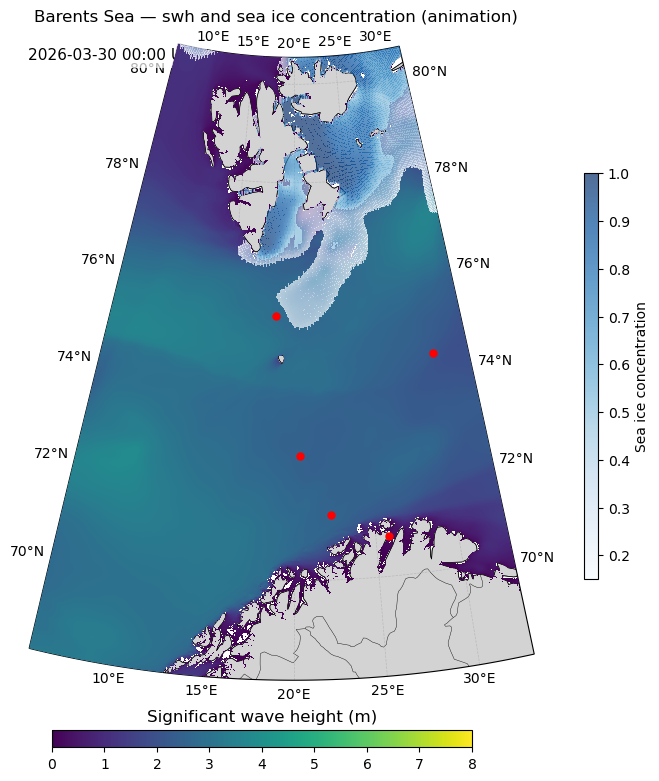

In [8]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

# Time window: last two days of March 2026
start_time = "2026-03-30 00:00:00"
end_time = "2026-03-30 23:59:59"

# Spatial window (same as previous map)
lat_slice = slice(68.0, 80.7)
lon_slice = slice(5.0, 33.0)

swh_anim = monthly_data["swh"].sel(time=slice(start_time, end_time), latitude=lat_slice, longitude=lon_slice)
ice_anim = monthly_data["ice"].sel(time=slice(start_time, end_time), latitude=lat_slice, longitude=lon_slice)

# Keep only common timestamps between variables
times = pd.DatetimeIndex(np.intersect1d(swh_anim.time.values, ice_anim.time.values))
if len(times) == 0:
    raise ValueError("No overlapping timesteps found for swh and ice in the selected period.")

lon_2d_anim, lat_2d_anim = np.meshgrid(swh_anim["longitude"].values, swh_anim["latitude"].values)

fig, ax = plt.subplots(
    1, 1,
    figsize=(7, 7),
    subplot_kw={
        "projection": ccrs.NearsidePerspective(
            central_longitude=20.0,
            central_latitude=72.0,
            satellite_height=2.5e7,
        )
    },
    constrained_layout=True,
)

ax.set_extent([5.0, 33.0, 68.0, 80.7], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="lightgray", edgecolor="black", linewidth=0.4, zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.5, zorder=2)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.3, zorder=2)
ax.gridlines(draw_labels=True, linestyle="--", linewidth=0.5, alpha=0.7)

lon_bounds = np.array([swh_anim["longitude"].values[0], swh_anim["longitude"].values[-1]])
lat_bounds = np.array([swh_anim["latitude"].values[0], swh_anim["latitude"].values[-1]])
boundary_path = Path(
    np.array([
        [lon_bounds[0], lat_bounds[0]],
        [lon_bounds[1], lat_bounds[0]],
        [lon_bounds[1], lat_bounds[1]],
        [lon_bounds[0], lat_bounds[1]],
        [lon_bounds[0], lat_bounds[0]],
    ]),
    closed=True,
)
ax.set_boundary(boundary_path.interpolated(100), transform=ccrs.PlateCarree())

# Plot fixed points
for lat, lon in zip(POINTS_LAT, POINTS_LON):
    ax.plot(lon, lat, marker="o", color="red", markersize=5, transform=ccrs.PlateCarree(), zorder=6)

# First frame
t0 = times[0]
swh0 = swh_anim["swh"].sel(time=t0).where(np.isfinite(swh_anim["swh"].sel(time=t0)))
ice0 = ice_anim["ice"].sel(time=t0).where(ice_anim["ice"].sel(time=t0) >= 0.15)

artists = {}
artists["swh"] = ax.pcolormesh(
    lon_2d_anim, lat_2d_anim, swh0.values,
    shading="auto", cmap="viridis", vmin=0, vmax=8,
    transform=ccrs.PlateCarree(), zorder=3,
)
artists["ice"] = ax.pcolormesh(
    lon_2d_anim, lat_2d_anim, ice0.values,
    shading="auto", cmap="Blues", vmin=0.15, vmax=1.0, alpha=0.7,
    transform=ccrs.PlateCarree(), zorder=4,
)

title_obj = ax.set_title("")
time_text = ax.text(
    0.02, 0.98, "", transform=ax.transAxes, va="top", ha="left",
    fontsize=11, bbox=dict(facecolor="white", alpha=0.7, edgecolor="none")
)

cax_ice = fig.add_axes([0.94, 0.18, 0.02, 0.58])
cax_swh = fig.add_axes([0.18, -0.06, 0.60, 0.025])
cb_ice = fig.colorbar(artists["ice"], cax=cax_ice, orientation="vertical")
cb_ice.set_label("Sea ice concentration")
cb_swh = fig.colorbar(artists["swh"], cax=cax_swh, orientation="horizontal")
cb_swh.ax.set_title("Significant wave height (m)")
cb_swh.ax.xaxis.set_ticks_position("bottom")
cb_swh.ax.xaxis.set_label_position("bottom")
cb_swh.ax.set_xlabel("")

def update(i):
    t = times[i]
    swh_frame = swh_anim["swh"].sel(time=t).where(np.isfinite(swh_anim["swh"].sel(time=t)))
    ice_frame = ice_anim["ice"].sel(time=t).where(ice_anim["ice"].sel(time=t) >= 0.15)

    artists["swh"].remove()
    artists["ice"].remove()

    artists["swh"] = ax.pcolormesh(
        lon_2d_anim, lat_2d_anim, swh_frame.values,
        shading="auto", cmap="viridis", vmin=0, vmax=8,
        transform=ccrs.PlateCarree(), zorder=3,
    )
    artists["ice"] = ax.pcolormesh(
        lon_2d_anim, lat_2d_anim, ice_frame.values,
        shading="auto", cmap="Blues", vmin=0.15, vmax=1.0, alpha=0.7,
        transform=ccrs.PlateCarree(), zorder=4,
    )

    title_obj.set_text("Barents Sea — swh and sea ice concentration (animation)")
    time_text.set_text(pd.Timestamp(t).strftime("%Y-%m-%d %H:%M UTC"))
    return artists["swh"], artists["ice"], time_text, title_obj

anim = FuncAnimation(fig, update, frames=len(times), interval=250, blit=False)

# Save GIF (portable in notebooks)
gif_name = "BarentsSea_swh_ice_2026-03-30_2026-03-31.gif"
anim.save(gif_name, writer=PillowWriter(fps=6), dpi=150)

HTML(anim.to_jshtml())

## Barents Sea point analysis (72°N, 25°E)

This section builds a continuous time series from the Safe@Sea forecast runs by keeping only the first 24 hours of each 2-day forecast and concatenating those segments. That gives a nearly continuous daily forecast stack for January-October 2026 at a single point in the Barents Sea.

We then use metocean-stats to compute:
- basic descriptive statistics for `swh`
- persistence of events where `swh > 2 m`
- a daily frequency / summary plot using `plot_statistics`

The point is chosen as a nearby grid cell to 72°N, 25°E using the nearest-neighbour lookup in the source dataset.


In [9]:
def nearest_point(ds: xr.Dataset, lat: float, lon: float, varname: str) -> xr.Dataset:
    lat_name = next((name for name in ds.coords if 'lat' in name.lower()), None)
    lon_name = next((name for name in ds.coords if 'lon' in name.lower()), None)
    if lat_name is None or lon_name is None:
        raise ValueError(f"Dataset does not expose a latitude/longitude pair. Available coords: {list(ds.coords)}")

    ds = ds.rename({lat_name: 'latitude', lon_name: 'longitude'})
    return ds.sel(latitude=lat, longitude=lon, method='nearest')[[varname]]


def point_series(varnames, lat, lon, init_dates, base_url):
    if isinstance(varnames, str):
        varnames = [varnames]

    frames = []
    for init_ts in init_dates:
        init_date = init_ts.date()
        start = pd.Timestamp(init_date)
        end = start + pd.Timedelta(hours=24)
        expected_times = pd.date_range(start=start, end=end - pd.Timedelta(hours=1), freq='h')

        series_by_var = {varname: pd.Series(np.nan, index=expected_times, dtype=float) for varname in varnames}

        for varname in varnames:
            fname = safeatsea_filename(varname, init_date)
            url = os.path.join(base_url, fname)
            try:
                ds = open_safeatsea_zarr(url)
                ds_point = nearest_point(ds, lat, lon, varname)
                ds_point = ds_point.sortby('time')
                first_24h = ds_point[varname].sel(time=slice(start, end)).reindex(time=expected_times)
                if first_24h.size > 0:
                    series_by_var[varname] = first_24h.to_series().reindex(expected_times)
            except Exception as exc:
                print(f"Skipped {init_date} [{varname}]: {exc}")

        frame = pd.DataFrame(series_by_var)
        frame = frame[~frame.index.duplicated(keep='first')]
        frames.append(frame)

    if not frames:
        raise ValueError("No valid first-24h forecast slices were found for the chosen point.")

    continuous = pd.concat(frames, axis=0).sort_index()
    continuous = continuous[~continuous.index.duplicated(keep='first')]
    return continuous

In [10]:
# define time range for the analysis: January 1, 2026 to October 31, 2026
MONTH_START = dt.date(2026, 1, 1)
MONTH_END = dt.date(2026, 10, 31)
INIT_DATES = pd.date_range(MONTH_START, MONTH_END, freq="D")
# extract the first 24h from each forecast and build a continuous time series
# locations of interest: Fisheries activity 1, Fisheries activity 2, Aquculture, Goliath, JOHAN CASTBERG
data={'fishery1':{'latlon':(75.3,18.6)},
    'fishery2':{'latlon':(74.33,30.4)},
    'aquaculture':{'latlon':(70.806,25.818)},
    'goliath':{'latlon':(71.3,22.3)},
    'johan_castberg':{'latlon':(72.5,20.4)}
    }
load_data=False

In [13]:
if load_data:
    for loc in data.keys():
        print(loc)
        POINT_LAT, POINT_LON = data[loc]['latlon']
        point_df = point_series(['icing', 'swh', 'ice'], POINT_LAT, POINT_LON, INIT_DATES, BASE_URL)
        data[loc]['icing'] = point_df['icing']
        data[loc]['swh'] = point_df['swh']
        data[loc]['ice'] = point_df['ice']
        point_df.to_xarray().to_netcdf(f'data/SafeAtSea_BarentsSea_{loc}_20260101_20261031.nc')
else:
    for loc in data.keys():
        print(loc)
        point_df = xr.open_dataset(f'data/SafeAtSea_BarentsSea_{loc}_20260101_20261031.nc')
        data[loc]['icing'] = point_df['icing'].to_dataframe()
        data[loc]['swh']   = point_df['swh'].to_dataframe()
        data[loc]['ice']   = point_df['ice'].to_dataframe()


fishery1
fishery2
aquaculture
goliath
johan_castberg


/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'swh' contains 1920 NaN value(s) (26.3%). Some methods may require gap-filling first.
  warnings.warn(



Basic descriptive statistics for swh at the fishery1 point:
              H_s (m)
Count     5376.000000
Missing   1920.000000
Mean         2.012173
Std          1.134083
Skewness     1.628158
Kurtosis     3.377139
Min          0.346000
p01          0.481000
p05          0.752000
p10          0.932000
p25          1.234000
p50          1.729000
p75          2.506000
p90          3.410000
p95          4.318000
p99          6.012500
Max          7.586000

Persistence of swh > 2 m by month for the fishery1 point:
H_s (m) above 2.0 m        mean         std    max     Yearly
Month                                                        
Jan                   11.000000    4.242641   14.0   2.403241
Feb                         NaN         NaN    NaN   0.000000
Mar                  224.666667  132.296384  375.0   3.604861
Apr                   42.571429   52.459054  129.0   8.411342
May                   31.500000   32.543817   96.0   7.209722
Jun                   16.400000    7.700649   24.0

/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'swh' contains 1656 NaN value(s) (22.7%). Some methods may require gap-filling first.
  warnings.warn(
/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'swh' contains 1656 NaN value(s) (22.7%). Some methods may require gap-filling first.
  warnings.warn(



Basic descriptive statistics for swh at the fishery2 point:
              H_s (m)
Count     5640.000000
Missing   1656.000000
Mean         2.152506
Std          1.266209
Skewness     1.582701
Kurtosis     3.280843
Min          0.000000
p01          0.608780
p05          0.786000
p10          0.875800
p25          1.242000
p50          1.862000
p75          2.700000
p90          3.718400
p95          4.718000
p99          6.969220
Max          8.376000

Persistence of swh > 2 m by month for the fishery2 point:
H_s (m) above 2.0 m        mean        std    max    Yearly
Month                                                      
Jan                    4.000000        NaN    4.0  1.201620
Feb                   74.333333   7.767453   83.0  3.604861
Mar                   95.285714  78.688657  222.0  8.411342
Apr                   36.666667  36.048116  101.0  7.209722
May                   32.250000  26.820834   94.0  9.612962
Jun                   16.857143  12.401997   35.0  8.411342
Jul 

/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'swh' contains 1656 NaN value(s) (22.7%). Some methods may require gap-filling first.
  warnings.warn(
/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'swh' contains 1656 NaN value(s) (22.7%). Some methods may require gap-filling first.
  warnings.warn(



Basic descriptive statistics for swh at the goliath point:
              H_s (m)
Count     5640.000000
Missing   1656.000000
Mean         2.106189
Std          1.296508
Skewness     1.985821
Kurtosis     5.370497
Min          0.000000
p01          0.524000
p05          0.832000
p10          0.962000
p25          1.235500
p50          1.732000
p75          2.566000
p90          3.752200
p95          4.612000
p99          7.472500
Max          9.586000

Persistence of swh > 2 m by month for the goliath point:
H_s (m) above 2.0 m        mean        std    max    Yearly
Month                                                      
Jan                    7.000000        NaN    7.0  1.201620
Feb                   48.666667  29.143324   76.0  3.604861
Mar                  117.166667  73.125691  255.0  7.209722
Apr                   51.666667  55.984522  144.0  7.209722
May                   21.571429  18.072605   51.0  8.411342
Jun                   24.000000  17.925773   43.0  4.806481
Jul   

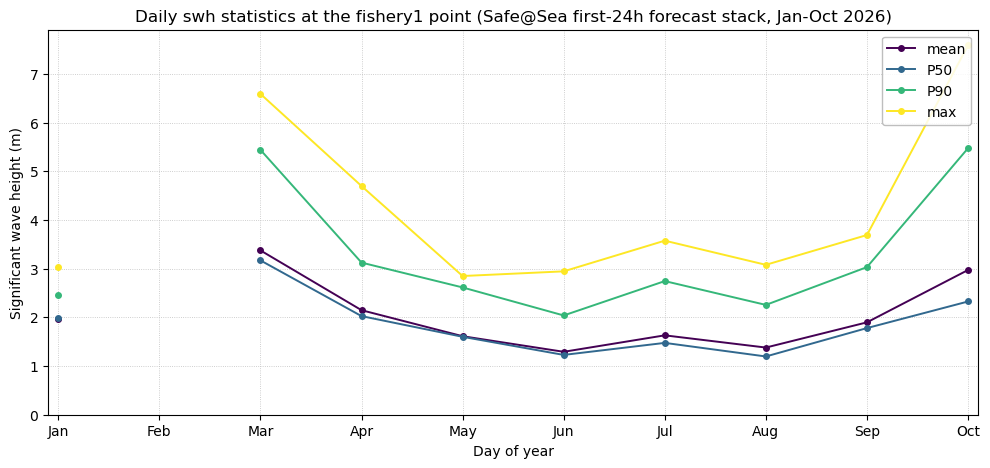

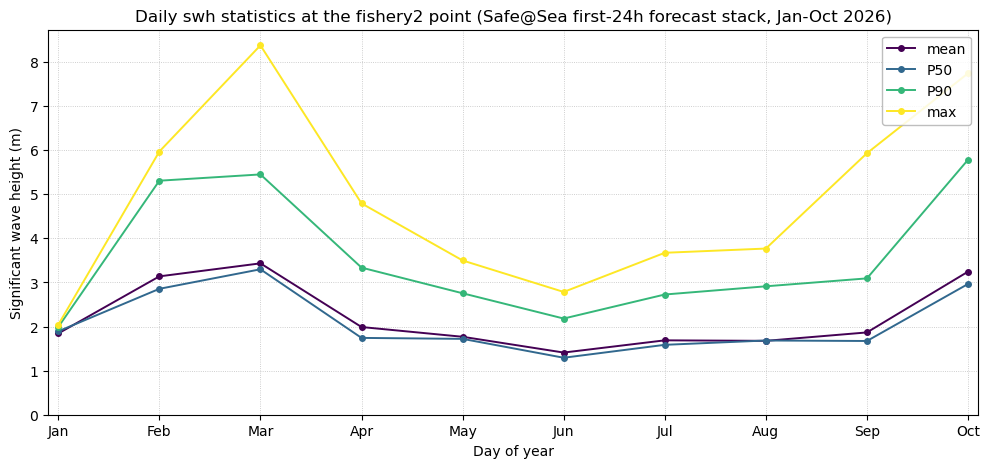

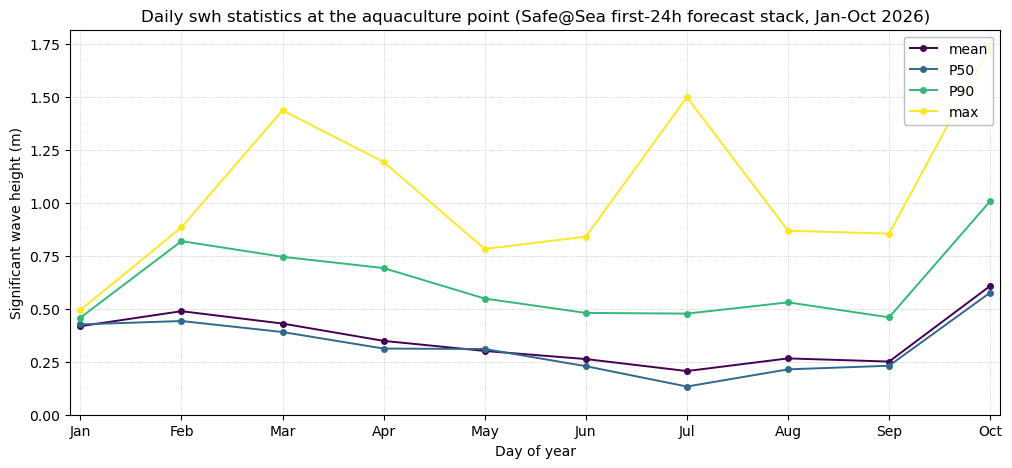

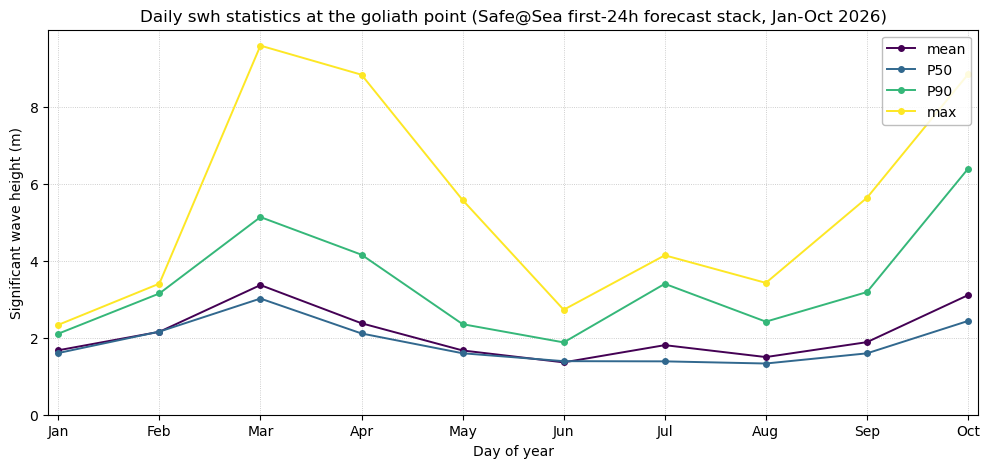

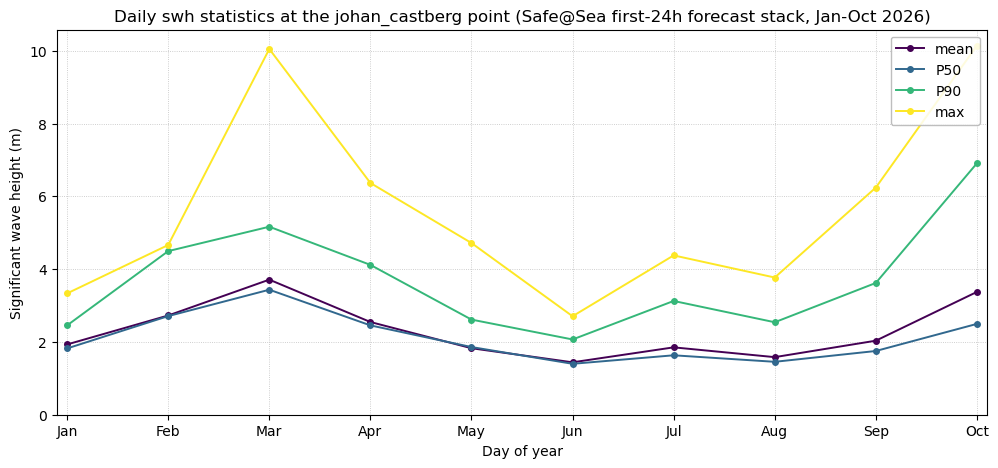

In [46]:
for loc in data.keys():
    # prepare the point series for metocean_stats
    point_df = data[loc]['swh']
    # metocean_stats.TimeSeries expects a DataFrame, not a Series
    if isinstance(point_df, pd.Series):
        point_df = point_df.to_frame(name="swh")

    point_ts = TimeSeries(
        df=point_df,
        primary=Variable('swh', 'Significant wave height', 'H_s', 'm'),
    )

    basic_stats = point_ts.describe()
    print(f'\nBasic descriptive statistics for swh at the {loc} point:')
    print(basic_stats)

    # persistence of swh > 2 m
    persistence_df = point_ts.persistence(
        threshold=2.0,
        above=True,
        by='month',
        variable='swh',
        stats=['mean', 'std', 'max'],
    )
    print(f'\nPersistence of swh > 2 m by month for the {loc} point:')
    print(persistence_df.head(10))

    # daily frequency/summary of swh using the plotting helper
    ax = point_ts.plot_statistics(
        by='month',
        variable='swh',
        stats=['mean', 'P50', 'P90', 'max'],
        figsize=(12, 5),
    )
    ax.set_title(f'Daily swh statistics at the {loc} point (Safe@Sea first-24h forecast stack, Jan-Oct 2026)')
    ax.set_xlabel('Day of year')
    ax.set_ylabel('Significant wave height (m)')
    ax.set_xlim(-0.1,9.1)
    plt.savefig(f"SafeAtSea_{loc}_swh_stats_JanOct_2026.png", dpi=300, bbox_inches="tight")

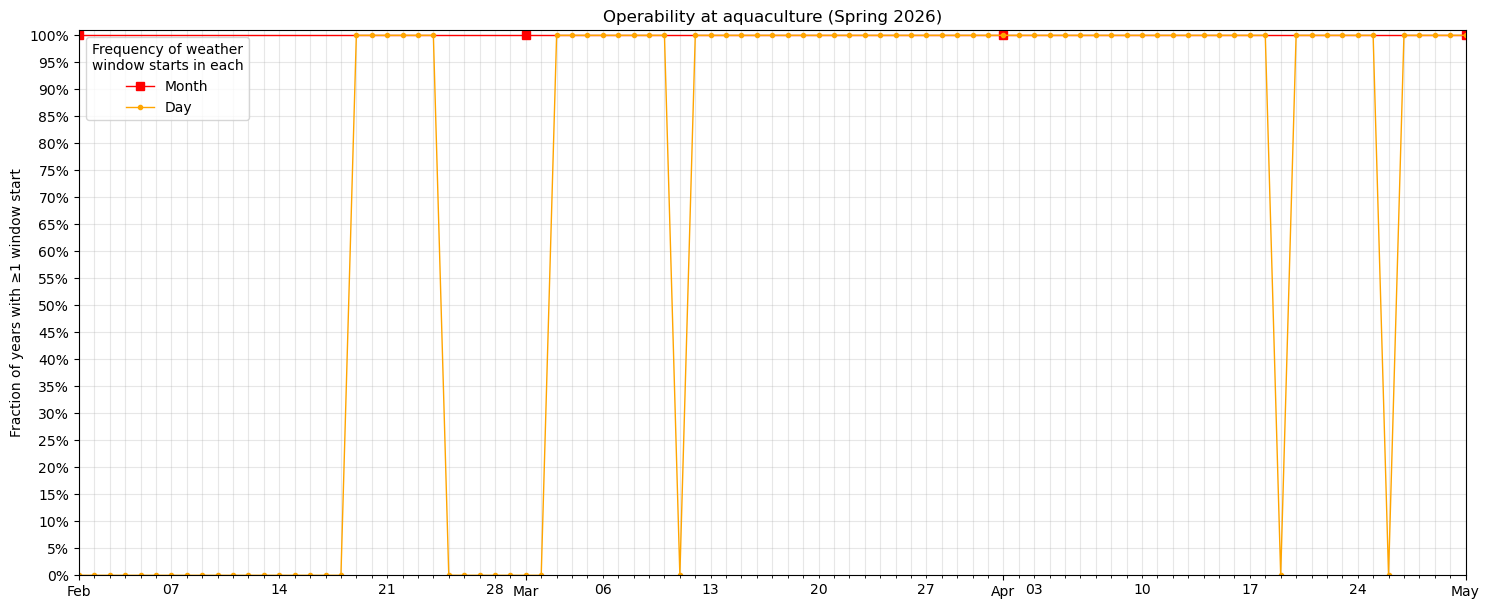

In [49]:
from metocean_stats.WW import WeatherWindow
loc='aquaculture'  # example location for the weather window analysis
# March-only weather window input at current location (loc)
march_swh = data[loc]["swh"]#[data[loc]["swh"].index.month == 3]
march_icing = data[loc]["icing"]#[data[loc]["icing"].index.month == 3]

# Build 1D Series for each variable and preserve the datetime index
hs = march_swh["swh"] if isinstance(march_swh, pd.DataFrame) else march_swh
icing = march_icing["icing"] if isinstance(march_icing, pd.DataFrame) else march_icing

# Align on common timestamps (important before WeatherWindow)
common_idx = hs.index.intersection(icing.index)

df = pd.DataFrame(index=common_idx)
df["hs"] = hs.reindex(common_idx)
df["icing"] = icing.reindex(common_idx)
df["dir"] = 0.0  # constant direction placeholder

# Optional if WeatherWindow should ignore missing values:
# df = df.dropna(subset=["hs", "icing"])

ww = WeatherWindow(df, timestep=1, direction="dir")
ww.fit(stages=[{"duration": 24, "criteria": {"hs": 2.0, "icing": 0.25}}])
# plot
fig, ax = plt.subplots(figsize=(15, 6))
ww.plot_operability(freqs=["M","D"], ax=ax,xlim=("02-01","05-01"))
ax.set_title(f"Operability at {loc} (Spring 2026)")
plt.savefig(f"SafeAtSea_{loc}_operability_Spring_2026.png", dpi=300, bbox_inches="tight")

/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'icing' contains 2046 NaN value(s) (28.0%). Some methods may require gap-filling first.
  warnings.warn(
/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'icing' contains 1704 NaN value(s) (23.4%). Some methods may require gap-filling first.
  warnings.warn(



Basic descriptive statistics for icing at the fishery1 point:
             I (mm/h)
Count     5250.000000
Missing   2046.000000
Mean         0.055080
Std          0.141272
Skewness     2.833672
Kurtosis     7.627069
Min          0.000000
p01          0.000000
p05          0.000000
p10          0.000000
p25          0.000000
p50          0.000000
p75          0.000000
p90          0.242752
p95          0.419317
p99          0.638581
Max          0.839494

Persistence of icing > 0.1 mm/h by month for the fishery1 point:
I (mm/h) above 0.1 mm/h       mean        std    max     Yearly
Month                                                          
Jan                      47.000000        NaN   47.0   1.201620
Feb                            NaN        NaN    NaN   0.000000
Mar                      26.333333  59.986867  212.0  14.419443
Apr                      45.166667  53.842053  133.0   7.209722
May                      19.555556  31.879112  100.0  10.814583
Jun                        

/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'icing' contains 1704 NaN value(s) (23.4%). Some methods may require gap-filling first.
  warnings.warn(
/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'icing' contains 1704 NaN value(s) (23.4%). Some methods may require gap-filling first.
  warnings.warn(



Basic descriptive statistics for icing at the goliath point:
             I (mm/h)
Count     5592.000000
Missing   1704.000000
Mean         0.001753
Std          0.017266
Skewness    11.641905
Kurtosis   145.334885
Min          0.000000
p01          0.000000
p05          0.000000
p10          0.000000
p25          0.000000
p50          0.000000
p75          0.000000
p90          0.000000
p95          0.000000
p99          0.052390
Max          0.278699

Persistence of icing > 0.1 mm/h by month for the goliath point:
I (mm/h) above 0.1 mm/h  mean       std   max    Yearly
Month                                                  
Jan                       3.0  0.000000   3.0  2.403241
Feb                      12.0  9.539392  22.0  3.604861
Mar                       NaN       NaN   NaN  0.000000
Apr                       NaN       NaN   NaN  0.000000
May                       NaN       NaN   NaN  0.000000
Jun                       NaN       NaN   NaN  0.000000
Jul                       NaN

/users/nummelin/metocean-stats/metocean_stats/timeseries.py:408: UserWarning: Column 'icing' contains 1704 NaN value(s) (23.4%). Some methods may require gap-filling first.
  warnings.warn(


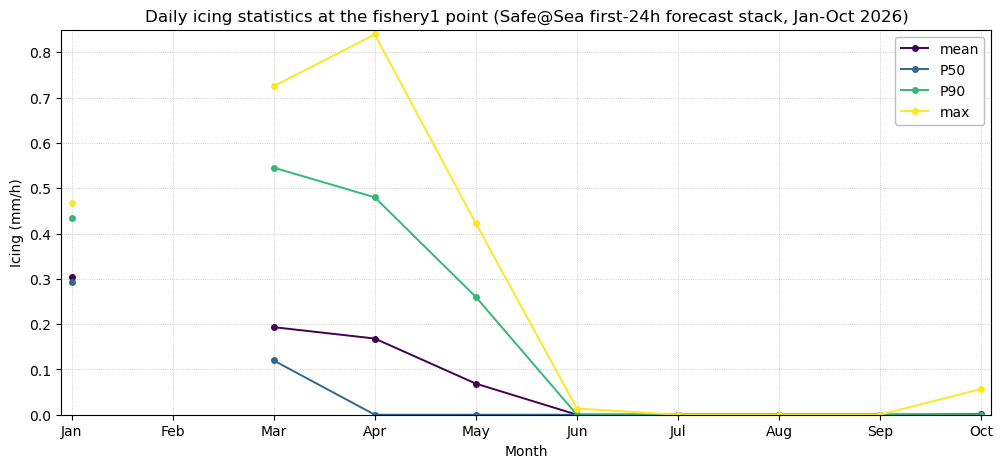

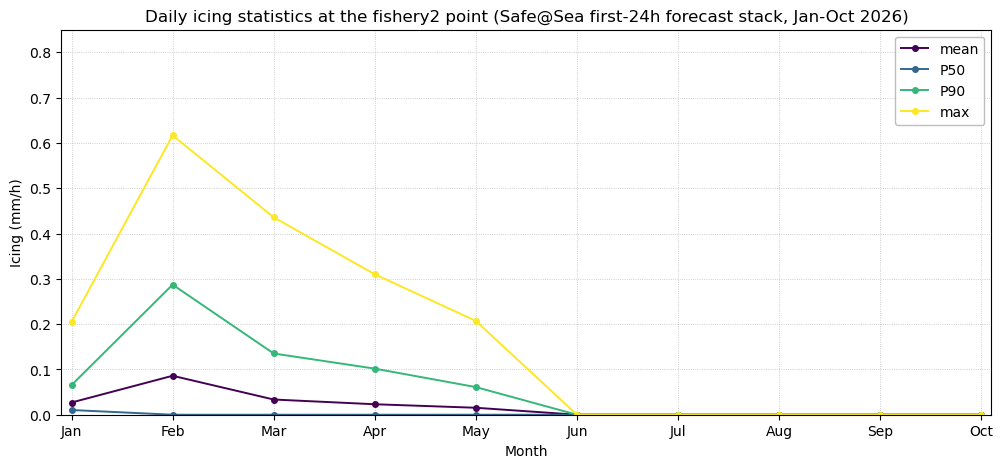

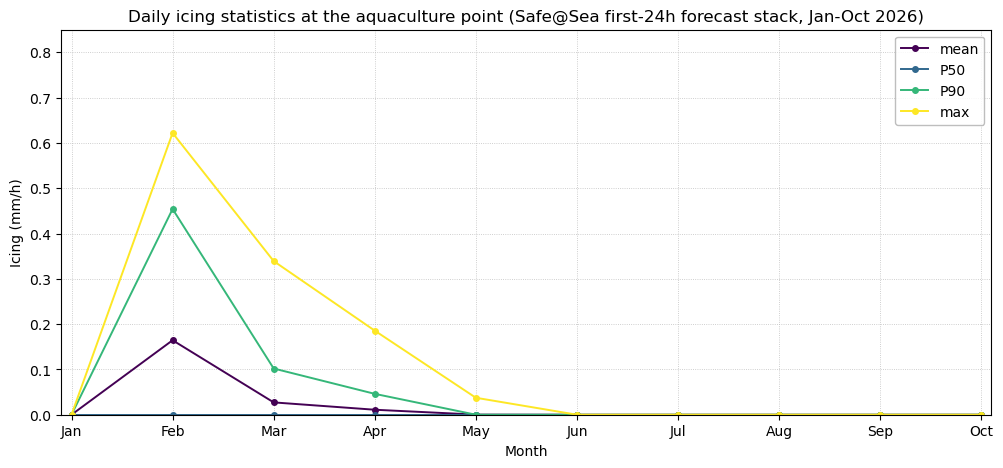

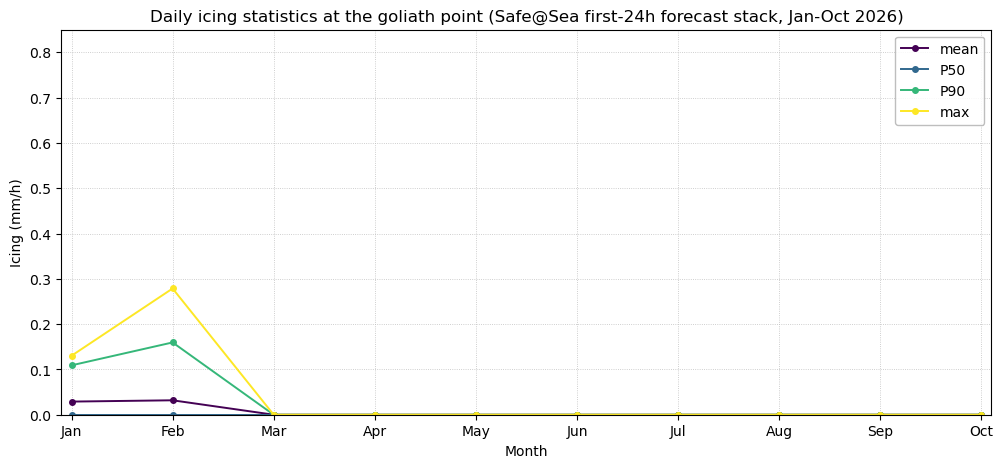

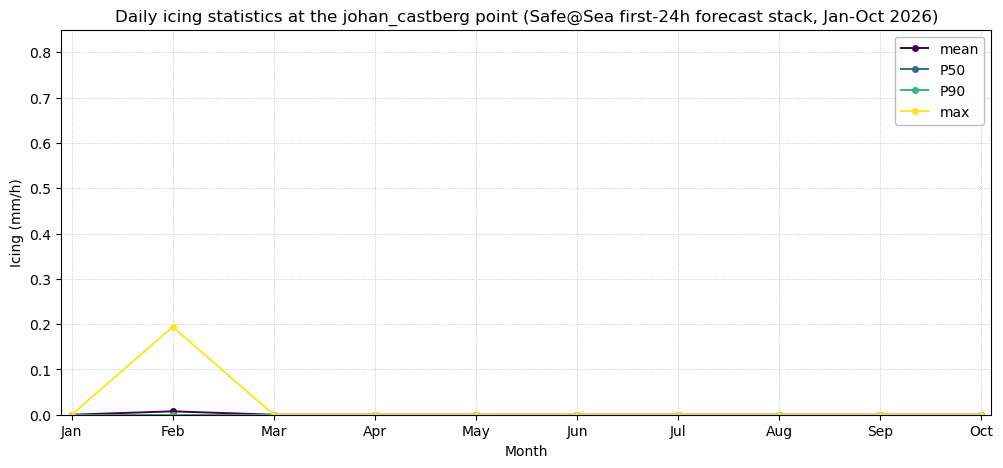

In [47]:
for loc in data.keys():
    # prepare the point series for metocean_stats
    point_df = data[loc]['icing']
    # metocean_stats.TimeSeries expects a DataFrame, not a Series
    if isinstance(point_df, pd.Series):
        point_df = point_df.to_frame(name="icing")

    point_ts = TimeSeries(
        df=point_df,
        primary=Variable('icing', 'Icing', 'I', 'mm/h'),
    )

    basic_stats = point_ts.describe()
    print(f'\nBasic descriptive statistics for icing at the {loc} point:')
    print(basic_stats)

    # persistence of icing > 0.1 mm/h
    persistence_df = point_ts.persistence(
        threshold=0.1,
        above=True,
        by='month',
        variable='icing',
        stats=['mean', 'std', 'max'],
    )
    print(f'\nPersistence of icing > 0.1 mm/h by month for the {loc} point:')
    print(persistence_df.head(10))

    # daily frequency/summary of icing using the plotting helper
    ax = point_ts.plot_statistics(
        by='month',
        variable='icing',
        stats=['mean', 'P50', 'P90', 'max'],
        figsize=(12, 5),
    )
    ax.set_ylim(0, 0.85)
    ax.set_title(f'Daily icing statistics at the {loc} point (Safe@Sea first-24h forecast stack, Jan-Oct 2026)')
    ax.set_xlabel('Month')
    ax.set_ylabel('Icing (mm/h)')
    ax.set_xlim(-0.1,9.1)
    plt.savefig(f"SafeAtSea_{loc}_icing_stats_JanOct_2026.png", dpi=300, bbox_inches="tight")

Timestamp('2026-01-01 00:00:00')